# General relativity 9: Cosmology

*Learning path: general relativity, part 9 of 9.* [Index](README.md) · Previous: [Gravitational waves](08-gravitational-waves.ipynb)

On the largest scales the universe looks the same everywhere and in every direction. General relativity then allows
only one kind of metric, one in which space as a whole expands. You will learn

* the Friedmann–Lemaître–Robertson–Walker (FLRW) metric and the scale factor $a(t)$ [1],
* what radiation, matter and a cosmological constant each do to the expansion, checked with Einstein's equations,
* how to compute the age of the universe, 13.8 billion years, from three numbers,
* when the cosmic microwave background was released.

## 1. The expanding universe

For a flat universe the FLRW metric is

$$ds^2 = -dt^2 + a(t)^2\left(dx^2 + dy^2 + dz^2\right)$$

$a(t)$ is the **scale factor**: distances between galaxies at rest in these coordinates grow in proportion to $a$. The
expansion rate is the **Hubble parameter** $H = \dot a/a$. Einstein's equations, applied to matter of density $\rho$ and
pressure $p$ that fills space evenly, become the Friedmann equations:

$$H^2 = \frac{8\pi G}{3}\rho, \qquad \text{and } G^x{}_x = 8\pi G\,p$$

We check them on three exact solutions.

## 2. Radiation: $a = \sqrt t$

In the hot early universe, radiation dominated. Try $a = \sqrt t$, so $a^2 = t$:

In [1]:
rad = metric([t x y z], [-1 0 0 0; 0 t 0 0; 0 0 t 0; 0 0 0 t])
einsteintensor(rad)

$$ds^2 = - \, dt^2 + t\, dx^2 + t\, dy^2 + t\, dz^2$$

**Einstein tensor** (coordinates $t$, $x$, $y$, $z$)

$$\begin{aligned}
G{}_{t}{}_{t} &= \frac{3}{4 t^{2}} \\
G{}_{x}{}_{x} &= \frac{1}{4 t} \\
G{}_{y}{}_{y} &= \frac{1}{4 t} \\
G{}_{z}{}_{z} &= \frac{1}{4 t}
\end{aligned}$$

The density is $8\pi G\rho = G_{tt} = 3/(4t^2)$, and indeed $H = \dot a/a = 1/(2t)$ gives $3H^2 = 3/(4t^2)$. The pressure is
$8\pi G\,p = G_{xx}/g_{xx} = 1/(4t^2)$, exactly $\rho/3$: the pressure of a gas of light. And $\rho \propto 1/t^2 = 1/a^4$:
radiation thins out as the volume grows ($a^3$) and each photon is stretched to longer wavelength (another $a$).

## 3. Matter: $a \propto t^{2/3}$

For cold matter (dust: galaxies, dark matter) the solution is $a \propto t^{2/3}$. It is cleanest in *conformal time*
$\eta$, with $dt = a\,d\eta$, where $a = \eta^2$:

In [2]:
dust = metric([eta x y z], [-eta^4 0 0 0; 0 eta^4 0 0; 0 0 eta^4 0; 0 0 0 eta^4])
einsteintensor(dust)

$$ds^2 = - \eta^{4}\, d\eta^2 + \eta^{4}\, dx^2 + \eta^{4}\, dy^2 + \eta^{4}\, dz^2$$

**Einstein tensor** (coordinates $\eta$, $x$, $y$, $z$)

$$\begin{aligned}
G{}_{\eta}{}_{\eta} &= \frac{12}{\eta^{2}}
\end{aligned}$$

Only $G_{\eta\eta}$ is non-zero: **no pressure**, as it should be for dust. The density $8\pi G\rho = G_{\eta\eta}/a^2 =
12/\eta^6 \propto 1/a^3$: matter just thins out with the volume.

## 4. A cosmological constant: $a = e^{Ht}$

In [3]:
ds = metric([t x y z], [-1 0 0 0; 0 exp(2*H*t) 0 0; 0 0 exp(2*H*t) 0; 0 0 0 exp(2*H*t)])
einsteintensor(ds)

$$ds^2 = - \, dt^2 + e^{2 H t}\, dx^2 + e^{2 H t}\, dy^2 + e^{2 H t}\, dz^2$$

**Einstein tensor** (coordinates $t$, $x$, $y$, $z$)

$$\begin{aligned}
G{}_{t}{}_{t} &= 3 H^{2} \\
G{}_{x}{}_{x} &= -3 H^{2} e^{2 H t} \\
G{}_{y}{}_{y} &= -3 H^{2} e^{2 H t} \\
G{}_{z}{}_{z} &= -3 H^{2} e^{2 H t}
\end{aligned}$$

$8\pi G\rho = 3H^2$, constant, and $8\pi G\,p = G_{xx}/g_{xx} = -3H^2$: **negative pressure**, $p = -\rho$. This is a
cosmological constant (part 3), or *dark energy*: its density does not thin out at all, so once it dominates, the
expansion speeds up exponentially. It has been accelerating for about 6 billion years [2] (by the Friedmann equation
below, since redshift 0.65).

## 5. Our universe

Today's measured values [3]: the Hubble constant $H_0 = 67.7$ km/s/Mpc, and the fractions of the critical density in
matter, $\Omega_m = 0.31$, and dark energy, $\Omega_\Lambda = 0.69$ (radiation is $\Omega_r \approx 9\times10^{-5}$).
The Friedmann equation becomes

$$\dot a = H_0\, a\,\sqrt{\frac{\Omega_r}{a^4} + \frac{\Omega_m}{a^3} + \Omega_\Lambda}$$

$1/H_0$ in billions of years:

In [4]:
H0 = 67.7;
tH = eval(977.8/H0)

14.443131462333824

### The age of the universe

The age is $\int_0^1 da/\dot a$. In units of $1/H_0$, then in billions of years:

In [5]:
age = odesolve([1/(a*sqrt(9e-5/a^4 + 0.31/a^3 + 0.69))], [t], a, [0], 1e-8, 1)
eval(age*tH)

0.9548765679545691
13.791407801269978

**13.8 billion years**, the value quoted by the Planck satellite team (13.787 ± 0.020) [3].

### The history of the expansion

Solving the Friedmann equation forward in time (in billions of years) gives $a(t)$. For comparison, a universe with
matter only ($\Omega_m = 1$), which cosmologists assumed until 1998:

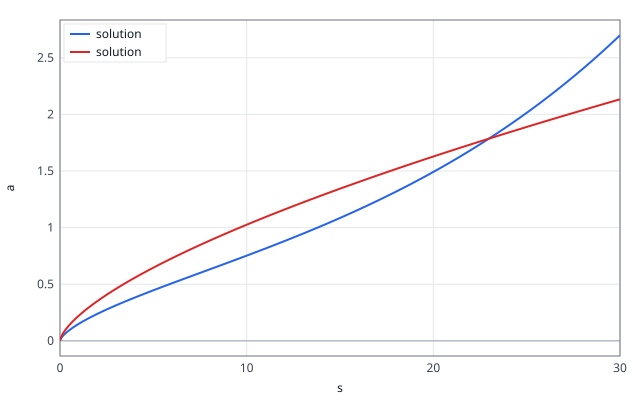

In [6]:
k = eval(H0/977.8);
ours = odeplot([k*a*sqrt(0.31/a^3 + 0.69), 1], [a s], t, [0.001 0], 0, 30, [s a]);
matteronly = odeplot([k*a*sqrt(1/a^3), 1], [a s], t, [0.001 0], 0, 30, [s a]);
show(ours, matteronly)

Our universe (first curve) reaches $a = 1$, today, at 13.8 billion years; at first the expansion slows down, like the
matter-only universe, then it bends upward and accelerates. The matter-only universe would be only 9.6 billion years old
today, younger than the oldest stars [4]. That conflict was one of the hints that led to dark energy.

### Looking back in time

Light from a galaxy at redshift $z$ left it when $a = 1/(1 + z)$. For $z = 1$, the age of the universe at emission, and
how long ago that was, in billions of years:

In [7]:
then = eval(odesolve([1/(a*sqrt(9e-5/a^4 + 0.31/a^3 + 0.69))], [t], a, [0], 1e-8, 0.5)*tH)
eval(13.8 - then)

5.856396864059484
7.943603135940517

### The cosmic microwave background

The universe was opaque until it cooled enough for hydrogen atoms to form, at $z \approx 1090$ [3]. The light released then
reaches us today as the cosmic microwave background, at 2.725 K [5]. Its temperature scales as $1/a$, so at release, in
kelvin, and the age of the universe at that moment, in years:

In [8]:
eval(2.725*1091)
eval(odesolve([1/(a*sqrt(9e-5/a^4 + 0.31/a^3 + 0.69))], [t], a, [0], 1e-8, 1/1091)*tH*1e9)

2972.975
372930.8160056529

About 3 000 K, as hot as the surface of a cool star, about 370 000 years after the Big Bang (by this simple calculation).

## Summary

* The FLRW metric $-dt^2 + a(t)^2\,d\vec x^2$ describes a uniform expanding universe.
* Einstein's equations give $\rho \propto a^{-4}$ and $p = \rho/3$ for radiation, $\rho \propto a^{-3}$ and $p = 0$ for
  matter, and constant $\rho$ with $p = -\rho$ for a cosmological constant.
* The Friedmann equation with $H_0$, $\Omega_m$, $\Omega_\Lambda$ gives an age of 13.8 billion years and an accelerating
  expansion today.

**This is the end of the general relativity path.** Everything here came from one idea, that gravity is the geometry
of spacetime, worked out with metrics, Christoffel symbols, geodesics and curvature: the tools of the
[differential geometry path](../differential-geometry/README.md).

## Sources

Numbers in square brackets in the text refer to this list.

1. A. Friedmann, "Über die Krümmung des Raumes", *Zeitschrift für Physik* **10**, 377–386 (1922), [doi:10.1007/BF01332580](https://doi.org/10.1007/BF01332580); G. Lemaître, *Annales de la Société Scientifique de Bruxelles* **47A**, 49–59 (1927); H. P. Robertson, *Astrophysical Journal* **82**, 284 (1935); A. G. Walker, *Proc. London Math. Soc.* **42**, 90 (1937).
2. A. G. Riess et al., *Astronomical Journal* **116**, 1009 (1998), [doi:10.1086/300499](https://doi.org/10.1086/300499); S. Perlmutter et al., *Astrophysical Journal* **517**, 565 (1999), [doi:10.1086/307221](https://doi.org/10.1086/307221).
3. Planck Collaboration, "Planck 2018 results. VI. Cosmological parameters", *Astronomy & Astrophysics* **641**, A6 (2020): H₀ = 67.66, Ω_m = 0.3111, Ω_Λ = 0.6889, age 13.787 Gyr, z* = 1089.9. [doi:10.1051/0004-6361/201833910](https://doi.org/10.1051/0004-6361/201833910)
4. L. M. Krauss and B. Chaboyer, "Age estimates of globular clusters in the Milky Way: constraints on cosmology", *Science* **299**, 65–69 (2003): oldest clusters at least 11.2 Gyr. [doi:10.1126/science.1075631](https://doi.org/10.1126/science.1075631)
5. D. J. Fixsen, "The temperature of the cosmic microwave background", *Astrophysical Journal* **707**, 916 (2009): 2.72548 ± 0.00057 K. [doi:10.1088/0004-637X/707/2/916](https://doi.org/10.1088/0004-637X/707/2/916)
6. S. M. Carroll, *Spacetime and Geometry: An Introduction to General Relativity*, Addison-Wesley (2004). Chapter 8 (cosmology).